In [1]:
import os
import sys
import pickle
import random
import argparse
import numpy as np
import torch
from torch_geometric.loader import DataLoader

d:\git_repos\capstone\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\git_repos\capstone\.venv\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
BASE_DIR = r"d:\git_repos\capstone\attack-detection"
PARENT_DIR = os.path.dirname(BASE_DIR)
GT_DIR = os.path.join(PARENT_DIR, "graph-transformer")
if GT_DIR not in sys.path:
    sys.path.append(GT_DIR)
if BASE_DIR not in sys.path:
    sys.path.append(BASE_DIR)

In [3]:
from model import GraphTransformerAutoencoder, ModelConfig
from train import split_data, normalize_graph_features, align_graph_feature_dim, apply_saved_normalization
from detector import ZeroDayDetector, RiskState, DetectionResult
from scorer import AnomalyScorerConfig
from plot_confusion_matrix import plot_confusion_matrix
from plot_scenario_explainer import plot_scenario_explainer
from generate_confusion_explainer import generate_confusion_explainer_html

In [4]:
OUTPUTS_DIR = os.path.join(GT_DIR, "outputs")
GRAPH_DATA_PATH = os.path.join(OUTPUTS_DIR, "graphs.pt")
VOCAB_PATH = os.path.join(OUTPUTS_DIR, "vocab.pkl")
CHECKPOINT_PATH = os.path.join(OUTPUTS_DIR, "best_model.pt")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42

In [5]:
def _rank_data_numpy(a: np.ndarray) -> np.ndarray:
    a = np.asarray(a)
    n = len(a)
    if n == 0:
        return np.array([], dtype=np.float64)
    sorter = np.argsort(a)
    inv = np.empty(n, dtype=np.intp)
    inv[sorter] = np.arange(n)

    a_sorted = a[sorter]
    obs = np.r_[True, a_sorted[1:] != a_sorted[:-1]]
    dense = obs.cumsum()[inv]

    count = np.r_[np.nonzero(obs)[0], n]
    return 0.5 * (count[dense] + count[dense - 1] + 1)

In [6]:
def compute_roc_auc(scores: np.ndarray, labels: np.ndarray) -> float:
    scores = np.asarray(scores, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64)

    pos_scores = scores[labels == 1]
    neg_scores = scores[labels == 0]
    n_pos = len(pos_scores)
    n_neg = len(neg_scores)

    if n_pos == 0 or n_neg == 0:
        return 0.5

    all_scores = np.concatenate([pos_scores, neg_scores])
    all_labels = np.concatenate([np.ones(n_pos, dtype=np.int64), np.zeros(n_neg, dtype=np.int64)])
    ranks = _rank_data_numpy(all_scores)
    sum_pos_ranks = np.sum(ranks[all_labels == 1])
    u = sum_pos_ranks - (n_pos * (n_pos + 1.0)) / 2.0
    return float(u / (n_pos * n_neg))

In [7]:
def compute_pr_auc(scores: np.ndarray, labels: np.ndarray) -> float:
    scores = np.asarray(scores, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64)

    pos_count = int(np.sum(labels == 1))
    neg_count = int(np.sum(labels == 0))
    if pos_count == 0 or neg_count == 0:
        return 0.0

    desc_order = np.argsort(scores)[::-1]
    sorted_scores = scores[desc_order]
    sorted_labels = labels[desc_order]

    distinct_indices = np.where(np.diff(sorted_scores))[0]
    threshold_indices = np.r_[distinct_indices, sorted_labels.size - 1]

    tps = np.cumsum(sorted_labels == 1)[threshold_indices]
    fps = np.cumsum(sorted_labels == 0)[threshold_indices]

    precisions = tps / (tps + fps)
    recalls = tps / pos_count

    recalls = np.r_[0.0, recalls]
    precisions = np.r_[precisions[0] if len(precisions) > 0 else 1.0, precisions]

    trap_fn = getattr(np, "trapezoid", getattr(np, "trapz", None))
    return float(trap_fn(precisions, recalls))

In [8]:
def restore_or_split_graphs(graphs: list, checkpoint: dict):
    train_captures = checkpoint.get("train_captures")
    val_captures = checkpoint.get("val_captures")
    test_captures = checkpoint.get("test_captures")
    train_mean = checkpoint.get("train_mean")
    train_std = checkpoint.get("train_std")

    if train_captures and val_captures and test_captures and train_mean is not None and train_std is not None:
        print("Restoring exact capture splits and feature normalizer from checkpoint metadata...")
        train_graphs = [g for g in graphs if g.capture_name in train_captures]
        val_graphs = [g for g in graphs if g.capture_name in val_captures]
        test_graphs = [g for g in graphs if g.capture_name in test_captures or g.y.item() == 1 or not str(g.capture_name).startswith("ambient_")]
        apply_saved_normalization(train_graphs, train_mean, train_std)
        apply_saved_normalization(val_graphs, train_mean, train_std)
        apply_saved_normalization(test_graphs, train_mean, train_std)
        return train_graphs, val_graphs, test_graphs, train_mean, train_std
    else:
        print("Checkpoint lacks split metadata; falling back to deterministic split...")
        train_graphs, val_graphs, test_graphs, _, _, _ = split_data(graphs)
        mean, std = normalize_graph_features(train_graphs, val_graphs, test_graphs)
        return train_graphs, val_graphs, test_graphs, mean, std

In [9]:
def run_evaluation(scorer_config: AnomalyScorerConfig = None, show_plot: bool = True):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    print("=" * 70)
    print("ZERO-DAY CAN INTRUSION DETECTION EVALUATION")
    print("=" * 70)

    if not os.path.exists(GRAPH_DATA_PATH) or not os.path.exists(CHECKPOINT_PATH):
        raise FileNotFoundError(
            f"Missing graph data or model checkpoint in {OUTPUTS_DIR}. "
            f"Please run graph_builder.py and train.py first."
        )

    print("\n[1/4] Loading graphs, vocabulary, and model weights...")
    graphs = torch.load(GRAPH_DATA_PATH, weights_only=False)
    with open(VOCAB_PATH, "rb") as f:
        vocab = pickle.load(f)

    checkpoint = torch.load(CHECKPOINT_PATH, weights_only=False)
    config = ModelConfig()
    if "config" in checkpoint:
        for k, v in checkpoint["config"].items():
            if hasattr(config, k):
                setattr(config, k, v)
    config.num_ids = len(vocab)
    align_graph_feature_dim(graphs, config.node_stat_feature_dim)

    train_graphs, val_graphs, test_graphs, train_mean, train_std = restore_or_split_graphs(graphs, checkpoint)

    model = GraphTransformerAutoencoder(config).to(DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    print(f"Loaded {len(graphs)} total graphs. Vocab size: {len(vocab)}.")
    print(f"Split: {len(train_graphs)} train, {len(val_graphs)} val, {len(test_graphs)} test.")

    print("\n[2/4] Initializing and Calibrating Zero-Day Detector...")
    detector = ZeroDayDetector(scorer_config or AnomalyScorerConfig())
    detector.fit_baseline(train_graphs, vocab_size=len(vocab))

    val_loader = DataLoader(val_graphs, batch_size=1, shuffle=False)
    detector.calibrate(
        model, val_loader, device=DEVICE,
        suspicious_percentile=95.0,
        alert_percentile=99.0
    )

    print("\n[3/4] Evaluating Test Set (Held-Out Ambient Drives + 17 Attack Captures)...")
    test_loader = DataLoader(test_graphs, batch_size=1, shuffle=False)

    results: list[DetectionResult] = []
    with torch.no_grad():
        for batch in test_loader:
            batch = batch.to(DEVICE)
            outputs = model(
                x_stats=batch.x,
                id_idx=batch.id_idx,
                edge_index=batch.edge_index,
                edge_weight=batch.edge_attr,
            )
            res = detector.evaluate_graph(batch, outputs)
            results.append(res)

    print("\n[4/4] Computing Intrusion Detection Metrics...")
    scores = np.array([r.anomaly_score for r in results], dtype=np.float64)
    labels = np.array([r.ground_truth_label for r in results], dtype=np.int64)

    preds_binary = (scores >= detector.tau_suspicious).astype(int)

    tp = int(np.sum((preds_binary == 1) & (labels == 1)))
    fp = int(np.sum((preds_binary == 1) & (labels == 0)))
    tn = int(np.sum((preds_binary == 0) & (labels == 0)))
    fn = int(np.sum((preds_binary == 0) & (labels == 1)))

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * (precision * recall) / max(precision + recall, 1e-6)
    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    fpr = fp / max(fp + tn, 1)

    roc_auc = compute_roc_auc(scores, labels)
    pr_auc = compute_pr_auc(scores, labels)

    print("\n" + "=" * 70)
    print("OVERALL PERFORMANCE SUMMARY")
    print("=" * 70)
    print(f"  Total Test Windows      : {len(results)} (Benign: {np.sum(labels==0)}, Attack: {np.sum(labels==1)})")
    print(f"  True Positives          : {tp:5d}  |  False Positives (FP) : {fp:5d}")
    print(f"  False Negatives         : {fn:5d}  |  True Negatives (TN)  : {tn:5d}")
    print("-" * 70)
    print(f"  Decision Threshold      : {detector.tau_suspicious:.4f}")
    print(f"  High-Risk               : {detector.tau_alert:.4f}")
    print("-" * 70)
    print(f"  Precision               : {precision:.4f}")
    print(f"  Recall                  : {recall:.4f}")
    print(f"  F1-Score                : {f1:.4f}")
    print(f"  Accuracy                : {accuracy:.4f}")
    print(f"  False Positive Rate     : {fpr:.4f}")
    print("-" * 70)
    print(f"  ROC-AUC Discrimination  : {roc_auc:.4f}")
    print(f"  PR-AUC Score            : {pr_auc:.4f}")
    print("=" * 70)

    by_capture = {}
    for r in results:
        by_capture.setdefault(r.capture_name, []).append(r)

    print("\nPER-CAPTURE ZERO-DAY EVALUATION BREAKDOWN:")
    print(f"{'Capture Name':<45} | {'Type':<10} | {'Score Mean':<10} | {'Alerts/Total':<15} | {'Attack Hits':<12} | {'Latency':<8}")
    print("-" * 110)

    for cap_name in sorted(by_capture):
        cap_results = by_capture[cap_name]
        cap_scores = [r.anomaly_score for r in cap_results]
        cap_labels = [r.ground_truth_label for r in cap_results]
        is_attack_cap = any(y == 1 for y in cap_labels)
        cap_type = "ATTACK" if is_attack_cap else "BENIGN"

        triggered_count = sum(1 for s in cap_scores if s >= detector.tau_suspicious)
        total_windows = len(cap_results)

        latency_str = "N/A"
        if is_attack_cap:
            attack_start_times = [r.window_start for r in cap_results if r.ground_truth_label == 1]
            trigger_times = [r.window_start for r in cap_results if r.anomaly_score >= detector.tau_suspicious and r.ground_truth_label == 1]
            if attack_start_times and trigger_times:
                latency = max(0.0, trigger_times[0] - attack_start_times[0])
                latency_str = f"{latency:.2f}s"

        n_attack = sum(cap_labels)
        attack_hits = sum(1 for r in cap_results if r.ground_truth_label == 1 and r.anomaly_score >= detector.tau_suspicious)
        hits_str = f"{attack_hits}/{n_attack}" if n_attack else "-"

        print(f"{cap_name:<45} | {cap_type:<10} | {np.mean(cap_scores):<10.4f} | {f'{triggered_count}/{total_windows}':<15} | {hits_str:<12} | {latency_str:<8}")

    print("=" * 110)

    metrics = {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy,
        "fpr": fpr,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
    }

    cm_save_path = os.path.join(OUTPUTS_DIR, "xai_visuals", "confusion_matrix.png")
    plot_confusion_matrix(
        y_true=labels,
        y_pred=preds_binary,
        class_names=["Benign", "Attack"],
        metrics=metrics,
        title=f"Zero-Day CAN Intrusion Detection",
        save_path=cm_save_path,
        show=False,
    )

    scenario_counts = {
        "true_negative": tn,
        "false_positive": fp,
        "false_negative": fn,
        "true_positive": tp,
    }

    html_save_path = os.path.join(OUTPUTS_DIR, "xai_visuals", "scenario_explainer.html")
    generate_confusion_explainer_html(counts=scenario_counts, save_path=html_save_path)

    table_save_path = os.path.join(OUTPUTS_DIR, "xai_visuals", "scenario_explainer_table.png")
    plot_scenario_explainer(counts=scenario_counts, save_path=table_save_path, show=False)

    if show_plot:
        import webbrowser
        import matplotlib.pyplot as plt
        abs_html_path = "file:///" + os.path.abspath(html_save_path).replace("\\", "/")
        print(f"\nOpening Interactive Animated Scenario Explainer in browser: {abs_html_path}")
        webbrowser.open(abs_html_path)
        print("Displaying evaluation windows (Confusion Matrix and Scenario Table) - close windows to complete.")
        plt.show()

    return metrics

ZERO-DAY CAN INTRUSION DETECTION EVALUATION

[1/4] Loading graphs, vocabulary, and model weights...
Restoring exact capture splits and feature normalizer from checkpoint metadata...
Loaded 10996 total graphs. Vocab size: 106.
Split: 7990 train, 2101 val, 905 test.

[2/4] Initializing and Calibrating Zero-Day Detector...
Detector Calibrated on 2101 validation windows:
  tau_suspicious (95.0th percentile) : 0.7085
  tau_alert      (99.0th percentile) : 1.1295

[3/4] Evaluating Test Set (Held-Out Ambient Drives + 17 Attack Captures)...

[4/4] Computing Intrusion Detection Metrics...

OVERALL PERFORMANCE SUMMARY
  Total Test Windows      : 905 (Benign: 736, Attack: 169)
  True Positives          :   121  |  False Positives (FP) :    19
  False Negatives         :    48  |  True Negatives (TN)  :   717
----------------------------------------------------------------------
  Decision Threshold      : 0.7085
  High-Risk               : 1.1295
--------------------------------------------------

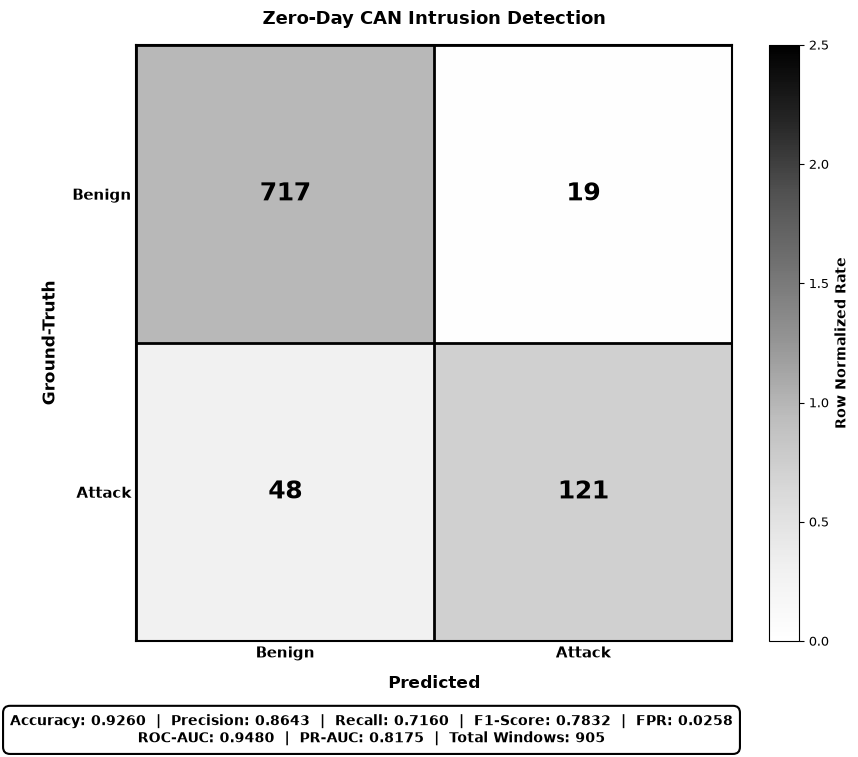

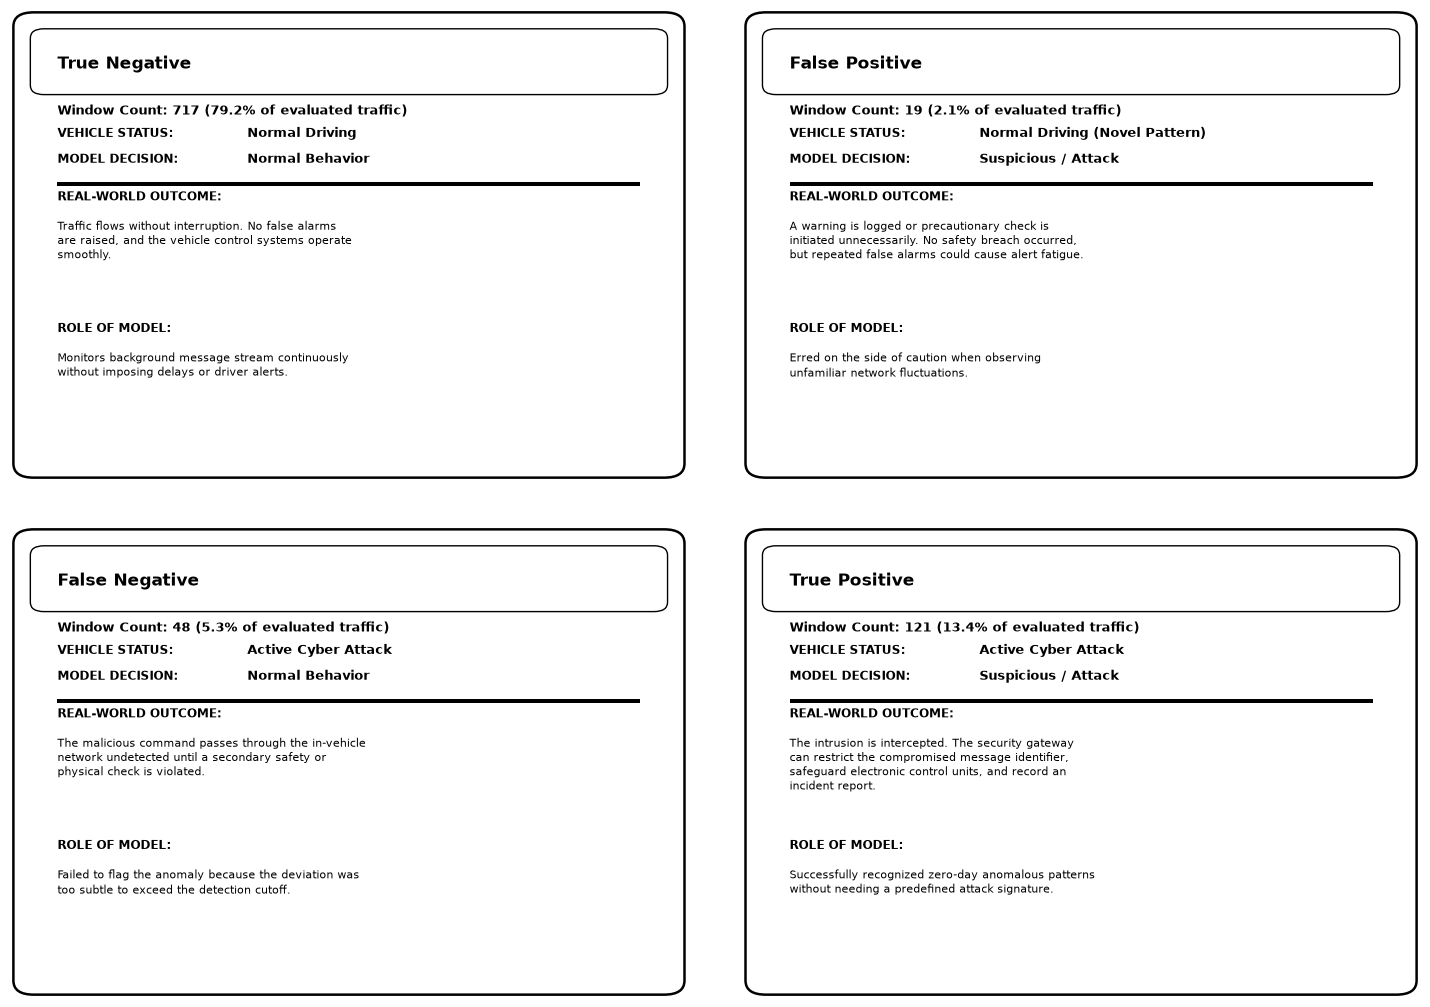

In [10]:
if __name__ == "__main__":
    run_evaluation(show_plot=False)
